In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from itertools import cycle
from collections import Counter
from scipy.stats import chi2_contingency
import os

In [ ]:
df = pd.read_csv("/content/Untitled form (Responses) - Form responses 1.csv")
df.columns = df.columns.str.strip()

In [ ]:
os.makedirs("Survey_Graphs", exist_ok=True)


In [ ]:

df = df.drop(columns=['Timestamp'])

In [ ]:
def plot_question(question, data, q_num):
    plt.figure(figsize=(8, 5))


    if data.astype(str).str.contains(',').any():
        exploded = data.dropna().str.split(',').explode().str.strip()
        counts = exploded.value_counts()
        counts.plot(kind='barh')
        plt.xlabel("Number of Selections")

    else:
        counts = data.value_counts()


        if q_num in [14, 15, 16, 17]:
            plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140)
            plt.title(f"Q{q_num}: {question}")
            plt.savefig(f"Survey_Graphs/Q{q_num}_Pie.png")
            plt.show()
            return


        elif q_num in [10, 11, 12, 13]:
            counts.plot(kind='bar')
            plt.ylabel("Responses")


        elif q_num in [6, 7, 8, 9]:
            counts.plot(kind='barh')
            plt.xlabel("Responses")

        else:
            counts.plot(kind='bar')
            plt.ylabel("Responses")

    plt.title(f"Q{q_num}: {question}", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"Survey_Graphs/Q{q_num}.png")
    plt.show()


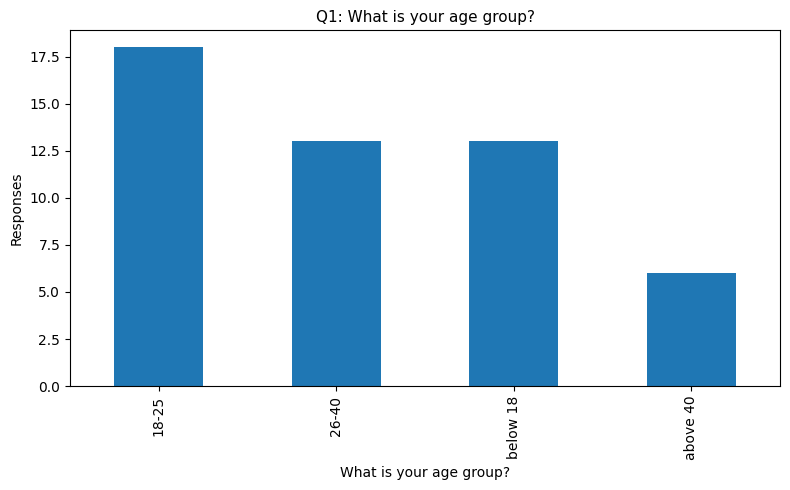

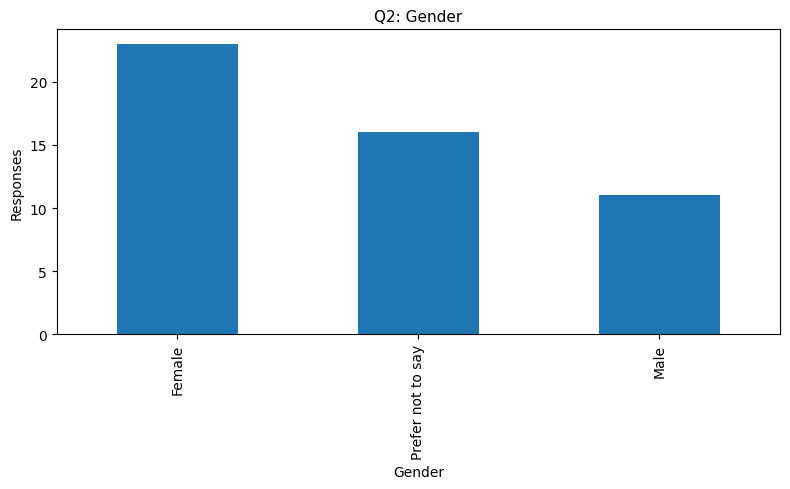

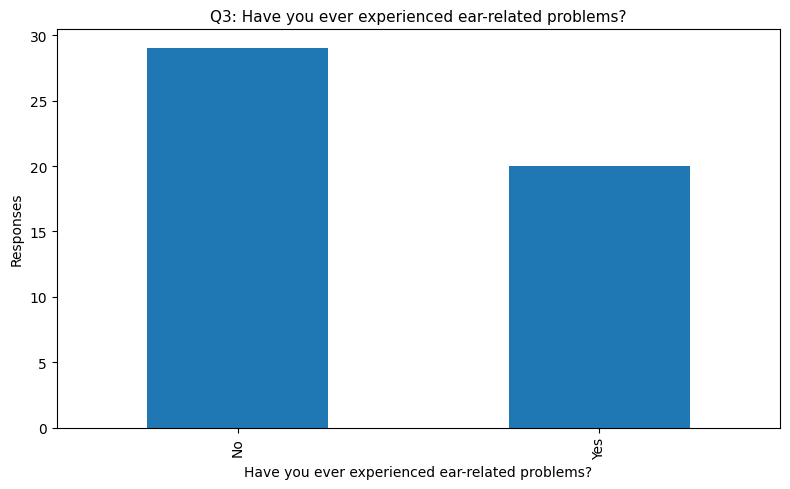

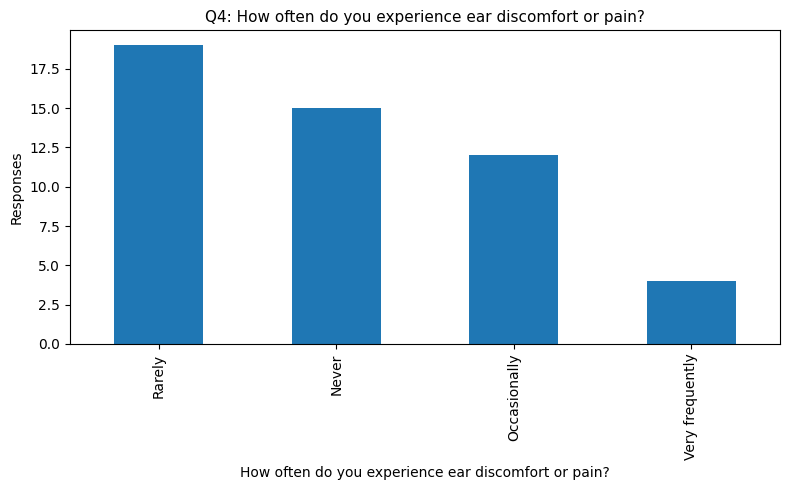

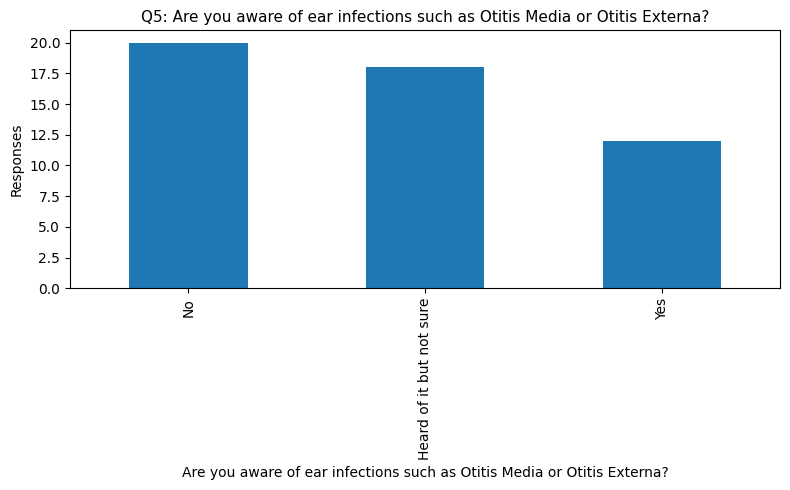

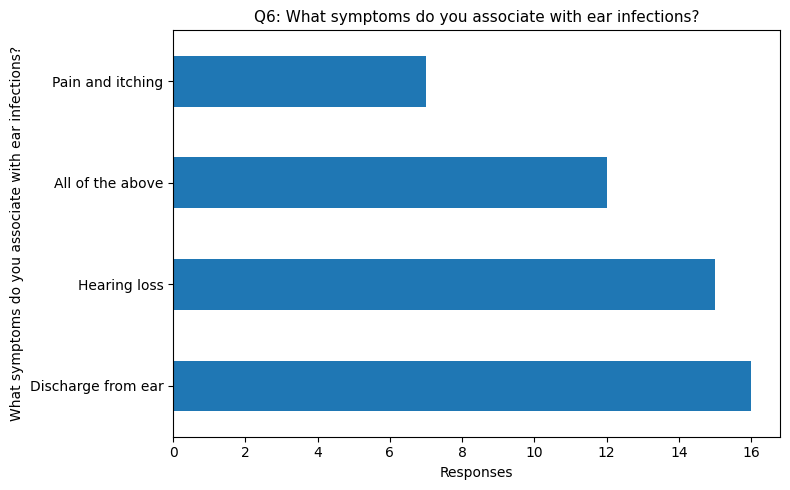

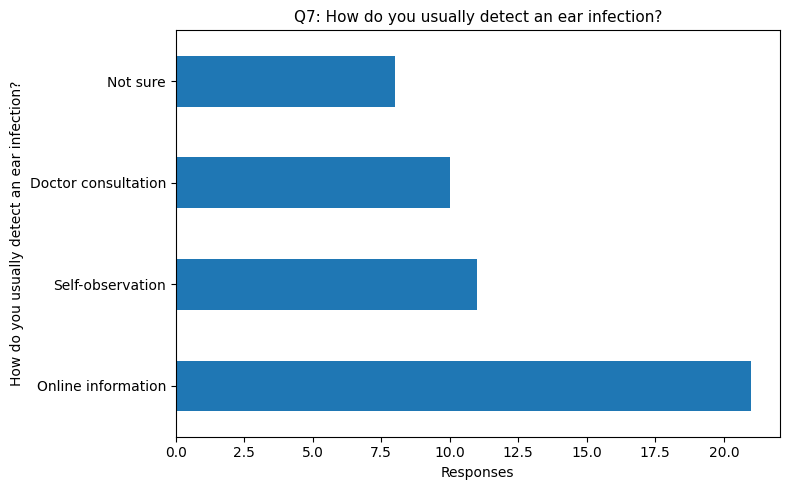

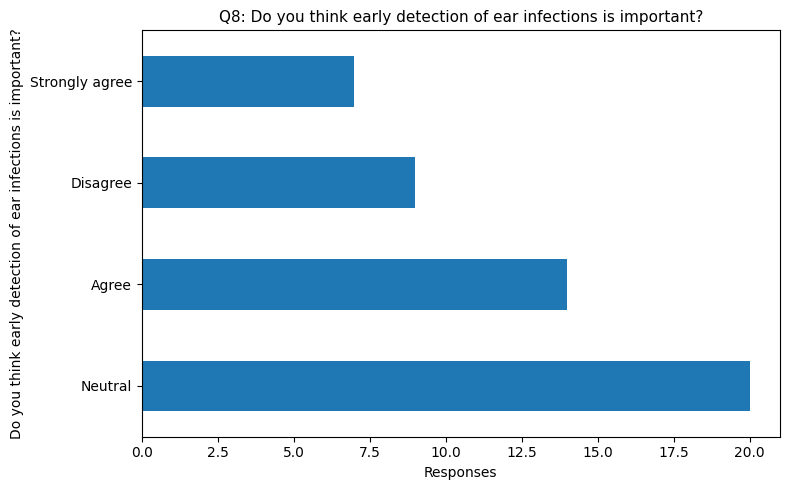

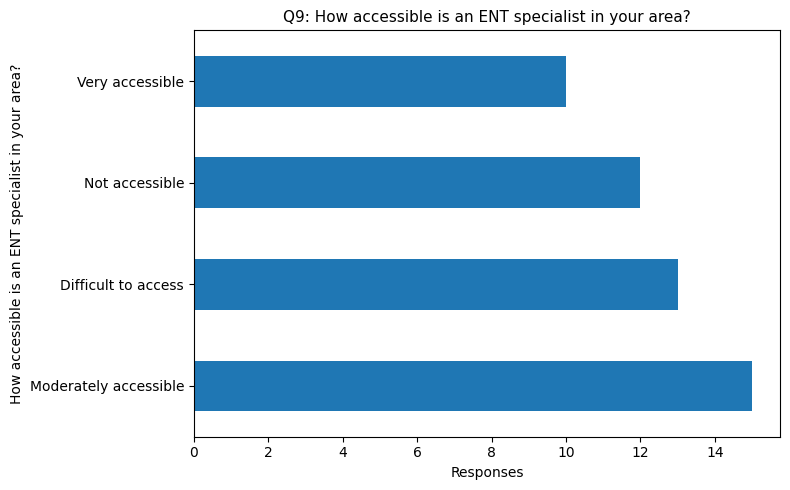

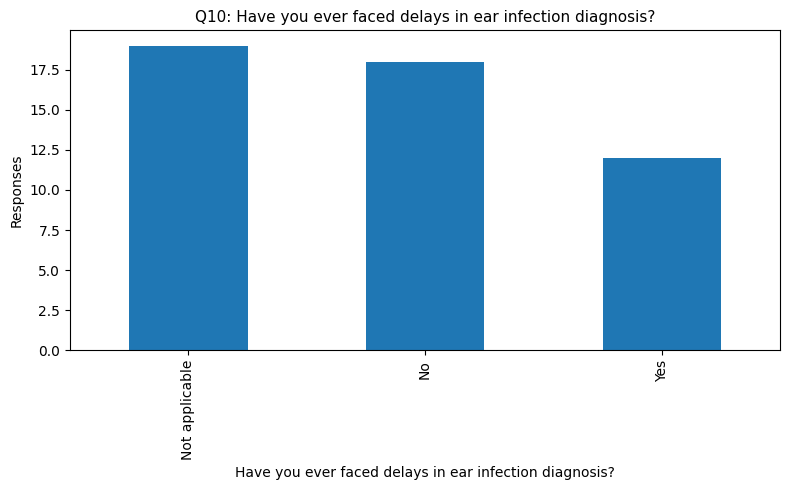

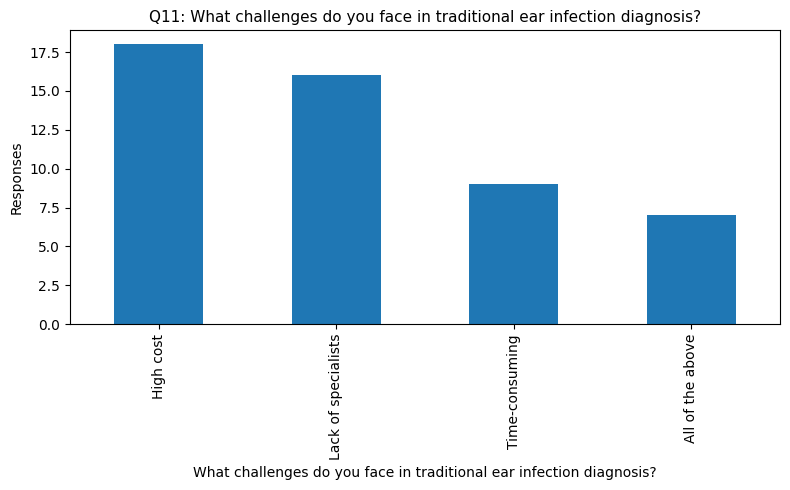

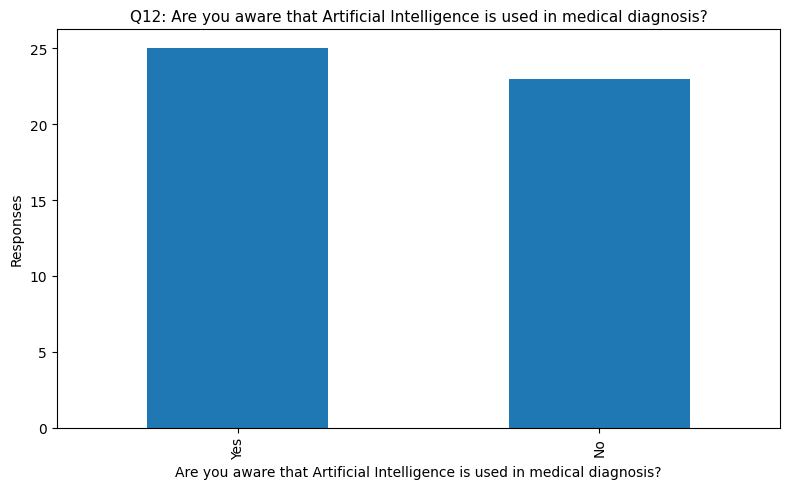

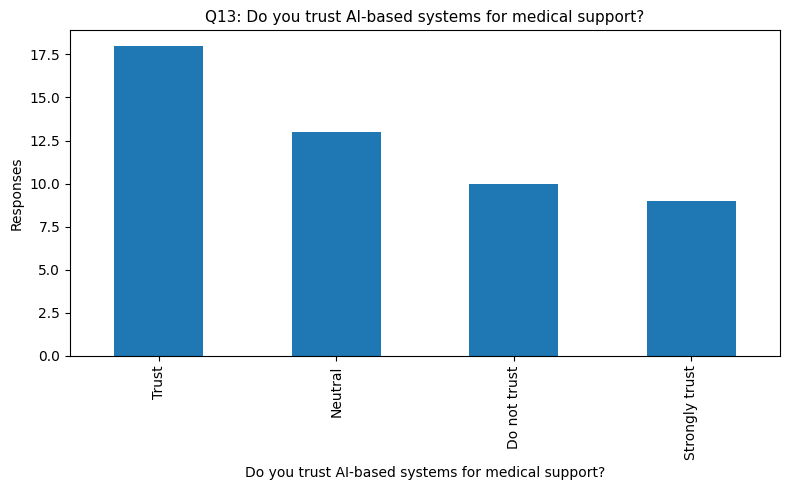

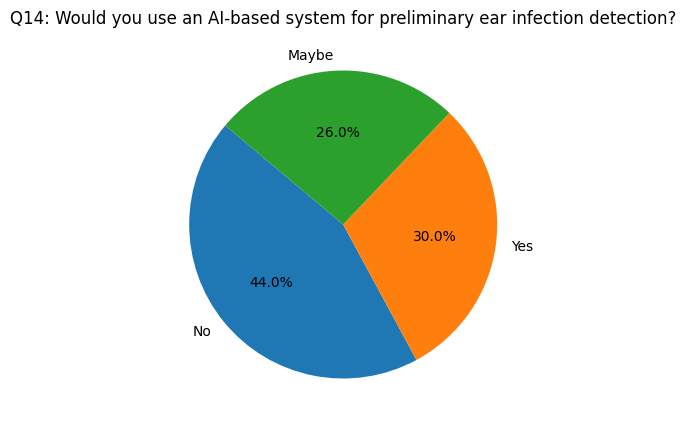

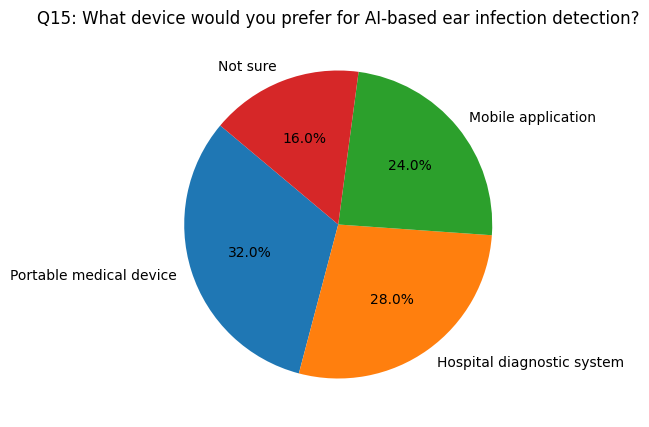

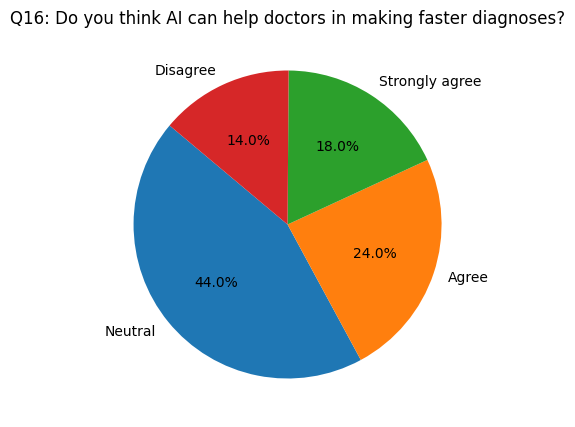

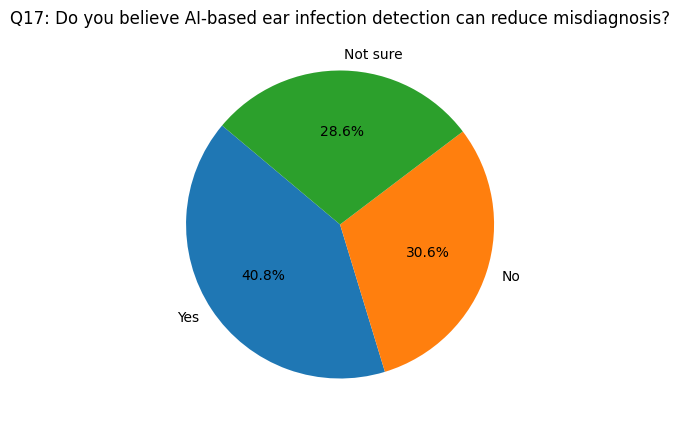

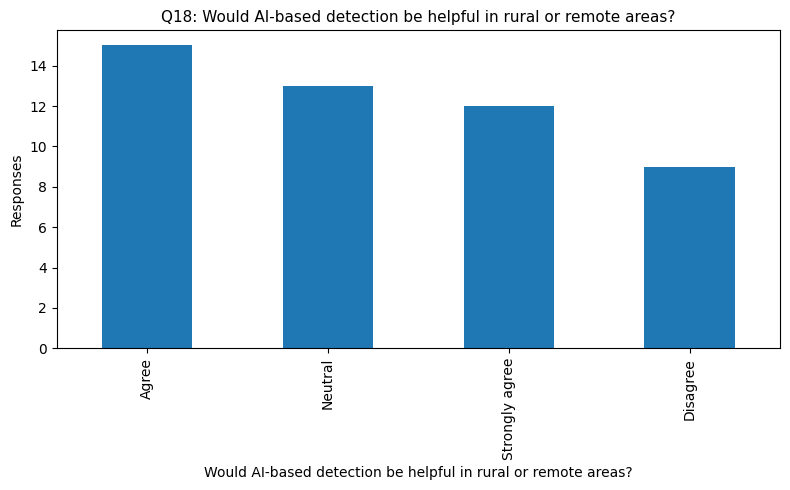

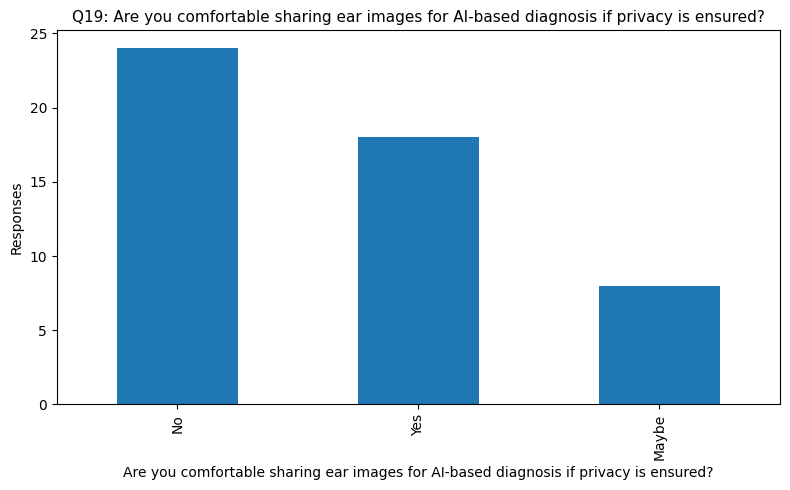

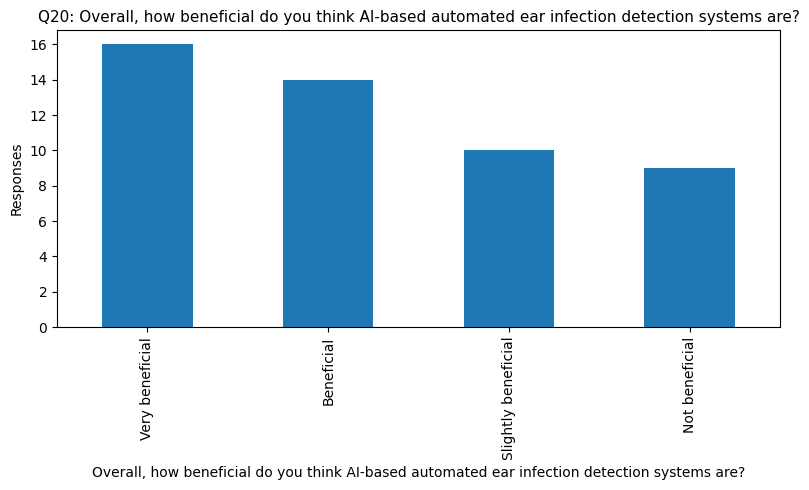

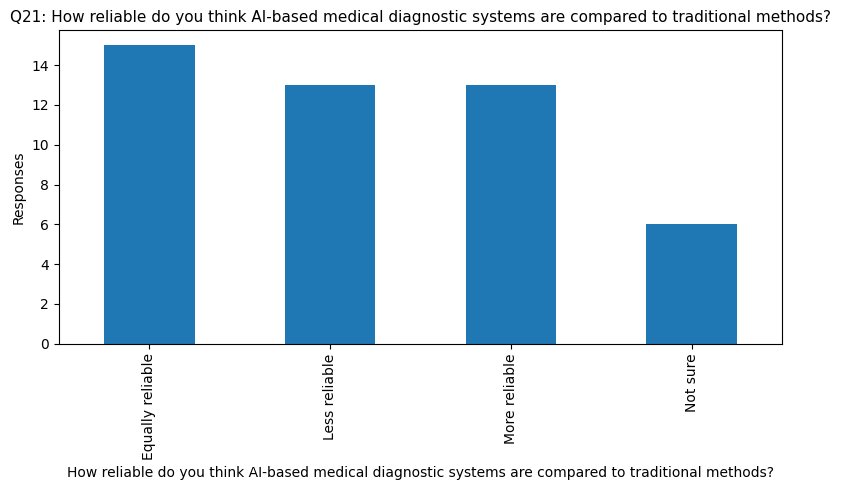

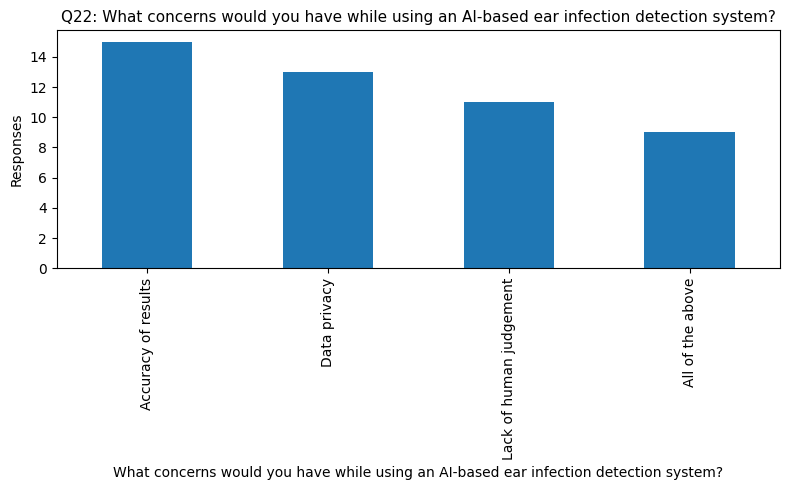

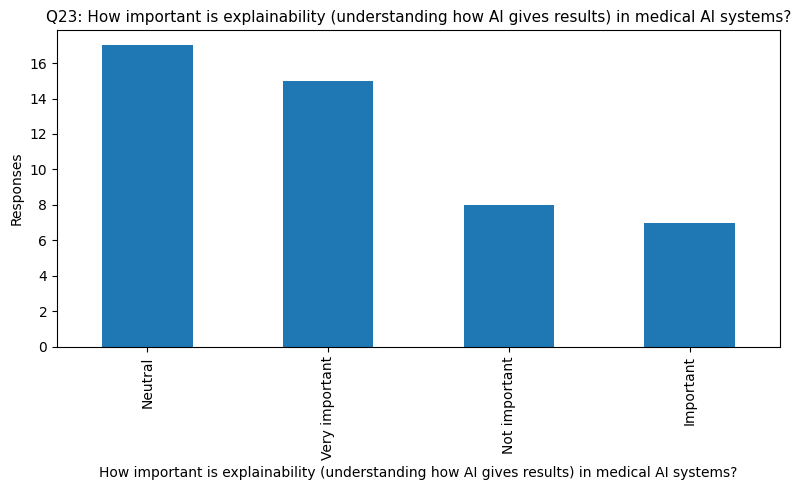

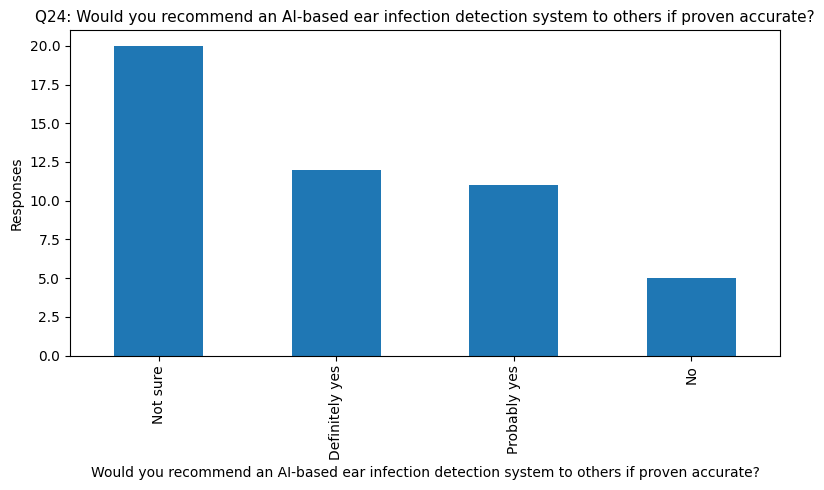

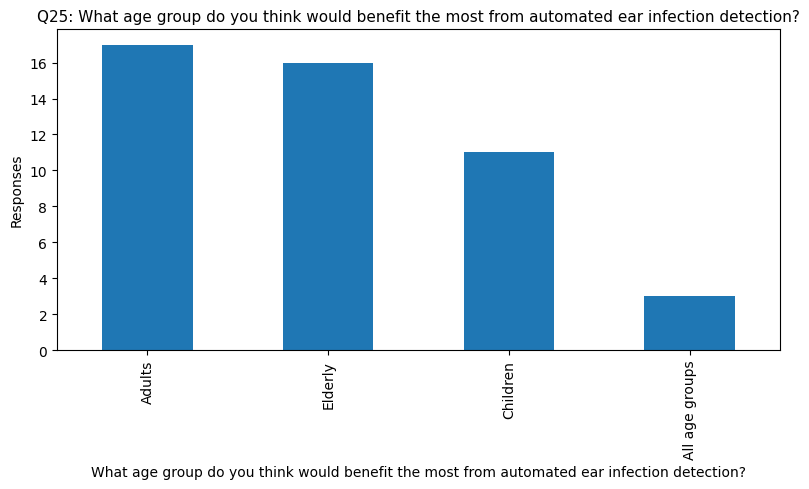

In [ ]:
for i, col in enumerate(df.columns[:25], start=1):
    plot_question(col, df[col], i)


In [ ]:
for col in df.columns:
    print(repr(col))

'What is your age group?'
'Gender'
'Have you ever experienced ear-related problems?'
'How often do you experience ear discomfort or pain?'
'Are you aware of ear infections such as Otitis Media or Otitis Externa?'
'What symptoms do you associate with ear infections?'
'How do you usually detect an ear infection?'
'Do you think early detection of ear infections is important?'
'How accessible is an ENT specialist in your area?'
'Have you ever faced delays in ear infection diagnosis?'
'What challenges do you face in traditional ear infection diagnosis?'
'Are you aware that Artificial Intelligence is used in medical diagnosis?'
'Do you trust AI-based systems for medical support?'
'Would you use an AI-based system for preliminary ear infection detection?'
'What device would you prefer for AI-based ear infection detection?'
'Do you think AI can help doctors in making faster diagnoses?'
'Do you believe AI-based ear infection detection can reduce misdiagnosis?'
'Would AI-based detection be helpf

In [ ]:
q1 = [c for c in df.columns if "trust" in c.lower() and "ai" in c.lower()][0]
q2 = [c for c in df.columns if "recommend" in c.lower()][0]

print("\nModel Columns Used:")
print("Q1:", q1)
print("Q2:", q2)


Model Columns Used:
Q1: Do you trust AI-based systems for medical support?
Q2: Would you recommend an AI-based ear infection detection system to others if proven accurate?


In [ ]:
table = pd.crosstab(df[q1], df[q2])
chi2, p, dof, exp = chi2_contingency(table)

print("\nChi-square value:", round(chi2,3))
print("p-value:", round(p,4))

if p < 0.05:
    print("Result: Significant relationship")
else:
    print("Result: No significant relationship")


Chi-square value: 4.411
p-value: 0.8824
Result: No significant relationship


In [ ]:
table = pd.crosstab(df[q1], df[q2])
chi2, p, dof, exp = chi2_contingency(table)

print("\nChi-square value:", round(chi2,3))
print("p-value:", round(p,4))

if p < 0.05:
    print("Result: Significant relationship")
else:
    print("Result: No significant relationship")


Chi-square value: 4.411
p-value: 0.8824
Result: No significant relationship


In [ ]:
mapping = {
    "Strongly Agree": 5, "Agree": 4, "Neutral": 3,
    "Disagree": 2, "Strongly Disagree": 1,
    "Definitely yes": 1, "Probably yes": 1,
    "Not sure": 0, "Probably no": 0, "Definitely no": 0
}

model_df = df[[q1, q2]].replace(mapping)
model_df = model_df.apply(pd.to_numeric, errors="coerce").dropna()

In [ ]:
if model_df[q1].nunique() > 1 and model_df[q2].nunique() > 1:
    spearman_corr = model_df[q1].corr(model_df[q2], method="spearman")
    print("Spearman Correlation (Trust → Adoption):", round(spearman_corr,3))
else:
    print("Spearman correlation also not applicable due to zero variance")

Spearman correlation also not applicable due to zero variance


In [ ]:
summary_tables = {}

for col in df.columns:
    counts = df[col].value_counts(dropna=True)
    percent = round((counts / counts.sum()) * 100, 2)
    summary = pd.DataFrame({"Count": counts, "Percentage": percent})
    summary_tables[col] = summary
    print(f"\nSummary for: {col}")
    print(summary)


Summary for: What is your age group?
                         Count  Percentage
What is your age group?                   
18-25                       18        36.0
26-40                       13        26.0
below 18                    13        26.0
above 40                     6        12.0

Summary for: Gender
                   Count  Percentage
Gender                              
Female                23        46.0
Prefer not to say     16        32.0
Male                  11        22.0

Summary for: Have you ever experienced ear-related problems?
                                                 Count  Percentage
Have you ever experienced ear-related problems?                   
No                                                  29       59.18
Yes                                                 20       40.82

Summary for: How often do you experience ear discomfort or pain?
                                                    Count  Percentage
How often do you experience ear 

In [ ]:
df.isnull().sum()

print("\nDuplicate responses:", df.duplicated().sum())



Duplicate responses: 0


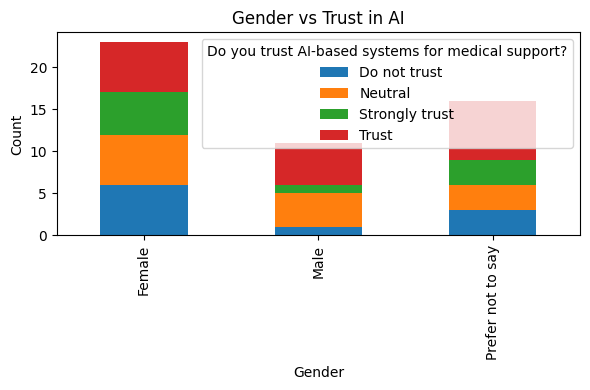

In [ ]:
ct = pd.crosstab(df["Gender"], df[q1])

ct.plot(kind="bar", stacked=True, figsize=(6,4))
plt.title("Gender vs Trust in AI")
plt.ylabel("Count")
plt.tight_layout()
plt.show()